In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
HORIZON = "1M"
K = 1
CLASSES = ["BUY", "HOLD", "SELL"]
AGENTS = ["financial", "sentiment", "macro"]
STANCE_TO_DIR = {"BULLISH": "BUY", "NEUTRAL": "HOLD", "BEARISH": "SELL"}

In [5]:
def read_jsonl(path: Path) -> list[dict]:
    rows = []
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if not line.strip(chr(0) + " "):
            continue
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            pass
    return rows


def cohen_kappa(y1: pd.Series, y2: pd.Series, classes: list[str] = CLASSES) -> float:
    n = len(y1)
    obs = float((y1 == y2).mean())
    s1 = y1.value_counts(normalize=True).reindex(classes, fill_value=0.0)
    s2 = y2.value_counts(normalize=True).reindex(classes, fill_value=0.0)
    chance = float((s1 * s2).sum())
    return (obs - chance) / (1.0 - chance) if chance < 1.0 else np.nan


def eval_summary(y_true: pd.Series, y_pred: pd.Series, ret_end: pd.Series) -> dict:
    n = len(y_true)
    acc = float((y_true == y_pred).mean())
    se = np.sqrt(acc * (1.0 - acc) / n)
    kappa = cohen_kappa(y_true, y_pred)
    dist = y_pred.value_counts(normalize=True).reindex(CLASSES, fill_value=0.0)
    mean_ret = ret_end.groupby(y_pred).mean().reindex(CLASSES) * 100
    return {
        "accuracy": acc,
        "acc_SE": se,
        "kappa": kappa,
        "BUY %": dist["BUY"],
        "HOLD %": dist["HOLD"],
        "SELL %": dist["SELL"],
        "ret BUY (%)": mean_ret["BUY"],
        "ret HOLD (%)": mean_ret["HOLD"],
        "ret SELL (%)": mean_ret["SELL"],
    }


EVAL_DIR = Path("../../datalake/evaluation")

In [7]:
KEY = ["ticker", "as_of", "horizon"]

labels = pd.DataFrame(read_jsonl(EVAL_DIR / f"labels_{HORIZON}_k{K}.jsonl"))
r1 = pd.DataFrame(read_jsonl(EVAL_DIR / "predictions_r1.jsonl"))
r2 = pd.DataFrame(read_jsonl(EVAL_DIR / "predictions_r2_debate_log.jsonl"))

r1 = r1[r1["direction"].notna()].drop_duplicates(KEY, keep="last")
r2 = r2[r2["direction"].notna()].drop_duplicates(KEY, keep="last")

df = (
    labels.merge(
        r1[KEY + ["direction", "confidence", "rounds_used", "critic_agreed"]].rename(
            columns={
                "direction": "dir_r1",
                "confidence": "conf_r1",
                "rounds_used": "rounds_r1",
                "critic_agreed": "agreed_r1",
            }
        ),
        on=KEY,
        how="inner",
    )
    .merge(
        r2[
            KEY
            + [
                "direction",
                "confidence",
                "rounds_used",
                "critic_agreed",
                "first_direction",
                "round_log",
            ]
        ].rename(
            columns={
                "direction": "dir_r2",
                "confidence": "conf_r2",
                "rounds_used": "rounds_r2",
                "critic_agreed": "agreed_r2",
                "first_direction": "first_dir_r2",
            }
        ),
        on=KEY,
        how="inner",
    )
)

df["as_of"] = pd.to_datetime(df["as_of"])
df["correct_r1"] = df["dir_r1"] == df["label"]
df["correct_r2"] = df["dir_r2"] == df["label"]
df["correct_r2_r1_pm"] = df["first_dir_r2"] == df["label"]

for ag in AGENTS:
    df[f"stance_r1_{ag}"] = df["round_log"].apply(lambda log: log[0]["stances"][ag])
    df[f"dir_r1_{ag}"] = df[f"stance_r1_{ag}"].map(STANCE_TO_DIR)


def majority_vote(row) -> str:
    votes = [row[f"dir_r1_{ag}"] for ag in AGENTS]
    counts = Counter(votes)
    top_vote, top_count = counts.most_common(1)[0]
    return top_vote if top_count >= 2 else "HOLD"


df["majority_vote_r1"] = df.apply(majority_vote, axis=1)
df["first_conf_r2"] = df["round_log"].apply(lambda log: log[0]["pm_confidence"])

print(f"Amount of complete samples: {len(df)}")
df[["ticker", "as_of", "label", "dir_r1", "first_dir_r2", "dir_r2"]].head()

Amount of complete samples: 190


,ticker,as_of,label,dir_r1,first_dir_r2,dir_r2
0,AAPL,2025-02-01,HOLD,HOLD,HOLD,HOLD
1,AAPL,2025-03-01,SELL,BUY,BUY,BUY
2,AAPL,2025-04-01,SELL,HOLD,BUY,BUY
3,AAPL,2025-05-01,HOLD,HOLD,BUY,BUY
4,AAPL,2025-06-01,HOLD,HOLD,HOLD,HOLD


=== Global metrics: r1 vs r2 ===


,r1,r2,diff (r2 - r1)
accuracy,0.452632,0.384211,-0.068421
acc_SE,0.036111,0.035288,-0.000823
kappa,0.032037,-0.064400,-0.096437
BUY %,0.252632,0.384211,0.131579
HOLD %,0.694737,0.594737,-0.100000
SELL %,0.052632,0.021053,-0.031579
ret BUY (%),2.861789,0.715966,-2.145822
ret HOLD (%),2.389846,4.321178,1.931332
ret SELL (%),11.743834,7.426300,-4.317534
always HOLD (baseline),0.494737,0.494737,0.000000



=== Precision and Recall for classes (r1 vs r2) ===


r1                              r2                        \
     precision    recall predictions precision    recall predictions   
BUY   0.312500  0.245902          48  0.273973  0.327869          73   
HOLD  0.530303  0.744681         132  0.469027  0.563830         113   
SELL  0.100000  0.028571          10  0.000000  0.000000           4   

     true_base_rate  
         proportion  
BUY        0.321053  
HOLD       0.494737  
SELL       0.184211

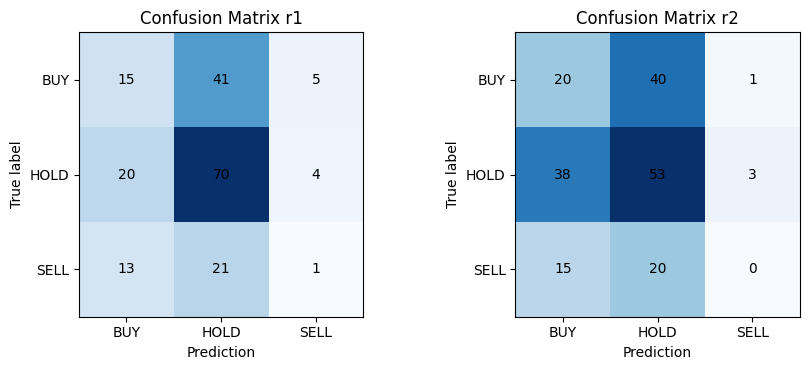

In [13]:
true_share = df["label"].value_counts(normalize=True).reindex(CLASSES, fill_value=0.0)

metrics_comp = pd.DataFrame(
    {
        "r1": eval_summary(df["label"], df["dir_r1"], df["ret_end"]),
        "r2": eval_summary(df["label"], df["dir_r2"], df["ret_end"]),
    }
)
metrics_comp.loc["always HOLD (baseline)"] = [true_share["HOLD"], true_share["HOLD"]]
metrics_comp["diff (r2 - r1)"] = metrics_comp["r2"] - metrics_comp["r1"]
print("=== Global metrics: r1 vs r2 ===")
display(metrics_comp)

conf_r1 = pd.crosstab(df["label"], df["dir_r1"]).reindex(
    index=CLASSES, columns=CLASSES, fill_value=0
)
conf_r2 = pd.crosstab(df["label"], df["dir_r2"]).reindex(
    index=CLASSES, columns=CLASSES, fill_value=0
)


def class_metrics(conf: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "precision": [
                conf.loc[c, c] / conf[c].sum() if conf[c].sum() else np.nan
                for c in CLASSES
            ],
            "recall": [
                conf.loc[c, c] / conf.loc[c].sum() if conf.loc[c].sum() else np.nan
                for c in CLASSES
            ],
            "predictions": conf.sum(axis=0).values,
        },
        index=CLASSES,
    )


per_class_comp = pd.concat(
    {"r1": class_metrics(conf_r1), "r2": class_metrics(conf_r2), "true_base_rate": true_share},
    axis=1,
)
print("\n=== Precision and Recall for classes (r1 vs r2) ===")
display(per_class_comp)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, conf, title in zip(axes, [conf_r1, conf_r2], ["Confusion Matrix r1", "Confusion Matrix r2"]):
    ax.imshow(conf.values, cmap="Blues")
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("Prediction")
    ax.set_ylabel("True label")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, conf.values[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

Worse results than before.

In [25]:
same_decision = (df["dir_r1"] == df["dir_r2"]).sum()
agreement_rate = same_decision / len(df)

print(
    f"Same decision r1 vs r2: {same_decision}/{len(df)} "
    f"({agreement_rate * 100:.1f}%)"
)

inter_matrix = pd.crosstab(
    df["dir_r1"], df["dir_r2"], rownames=["r1 direction"], colnames=["r2 direction"]
).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

print("\n=== Matrix between r1 and r2 ===")
display(inter_matrix)

Same decision r1 vs r2: 124/190 (65.3%)

=== Matrix between r1 and r2 ===


r2 direction,BUY,HOLD,SELL
r1 direction,,,
BUY,31,17,0
HOLD,41,90,1
SELL,1,6,3


Only 65% of the same decisions (quite low).

In [34]:
bins = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.01]
names = ["0.5-0.55", "0.55-0.6", "0.6-0.65", "0.65-0.7", "0.7-0.75", "0.75-0.8", "0.8-0.85", "0.85-0.9", "0.9-0.95", "0.95-1.0"]

df["conf_bin_r1"] = pd.cut(df["conf_r1"], bins=bins, labels=names, right=False)
df["conf_bin_r2"] = pd.cut(df["conf_r2"], bins=bins, labels=names, right=False)

cal_r1 = df.groupby("conf_bin_r1", observed=False)["correct_r1"].agg(
    n_r1="count", acc_r1="mean"
)
cal_r2 = df.groupby("conf_bin_r2", observed=False)["correct_r2"].agg(
    n_r2="count", acc_r2="mean"
)

print("=== (Confidence Calibration): r1 vs r2 ===")
display(pd.concat([cal_r1, cal_r2], axis=1))

ret_r1 = (
    df.groupby("dir_r1")["ret_end"].agg(["count", "mean", "median"]) * [1, 100, 100]
).reindex(CLASSES)
ret_r2 = (
    df.groupby("dir_r2")["ret_end"].agg(["count", "mean", "median"]) * [1, 100, 100]
).reindex(CLASSES)
ret_true = (
    df.groupby("label")["ret_end"].agg(["count", "mean", "median"]) * [1, 100, 100]
).reindex(CLASSES)

display(pd.concat({"r1": ret_r1, "r2": ret_r2, "true_label": ret_true}, axis=1))

=== (Confidence Calibration): r1 vs r2 ===


,n_r1,acc_r1,n_r2,acc_r2
0.5-0.55,2,0.500000,0,NaN
0.55-0.6,7,0.714286,2,1.000000
0.6-0.65,45,0.444444,42,0.380952
0.65-0.7,19,0.368421,14,0.571429
0.7-0.75,63,0.523810,82,0.378049
0.75-0.8,1,0.000000,1,0.000000
0.8-0.85,47,0.425532,40,0.400000
0.85-0.9,3,0.000000,7,0.000000
0.9-0.95,3,0.000000,2,0.000000
0.95-1.0,0,NaN,0,NaN


r1                         r2                     true_label  \
     count       mean    median count      mean    median      count   
BUY     48   2.861789  1.672559    73  0.715966  1.325453         61   
HOLD   132   2.389846  0.874643   113  4.321178  0.980959         94   
SELL    10  11.743834  8.246205     4  7.426300  8.767367         35   

                            
           mean     median  
BUY   17.459652  12.618840  
HOLD  -0.136042  -0.497458  
SELL -13.771056 -11.833539

The more confident model was, the more mistakes.

In [33]:
stance_Order = ["BULLISH", "NEUTRAL", "BEARISH"]
stance_dist = pd.DataFrame(
    {
        ag: df[f"stance_r1_{ag}"].value_counts().reindex(stance_Order, fill_value=0)
        for ag in AGENTS
    }
)
stance_dist_pct = stance_dist / len(df) * 100

print("=== Distribution of Agents' Stances in Round 1 (Count and Percentage) ===")
display(
    pd.concat({"count": stance_dist, "share (%)": stance_dist_pct}, axis=1)
)

agent_perf = {}
for ag in AGENTS:
    agent_perf[f"Agent: {ag}"] = eval_summary(
        df["label"], df[f"dir_r1_{ag}"], df["ret_end"]
    )


display(pd.DataFrame(agent_perf).T)

=== Distribution of Agents' Stances in Round 1 (Count and Percentage) ===


count                  share (%)                      
        financial sentiment macro  financial  sentiment      macro
BULLISH       112       126     0  58.947368  66.315789   0.000000
NEUTRAL        68        49   175  35.789474  25.789474  92.105263
BEARISH        10        15    15   5.263158   7.894737   7.894737

,accuracy,acc_SE,kappa,BUY %,HOLD %,SELL %,ret BUY (%),ret HOLD (%),ret SELL (%)
Agent: financial,0.389474,0.035376,0.021575,0.589474,0.357895,0.052632,4.240683,0.506812,6.084414
Agent: sentiment,0.336842,0.034288,-0.028218,0.663158,0.257895,0.078947,2.226997,0.743591,16.881752
Agent: macro,0.457895,0.036145,-0.023268,0.000000,0.921053,0.078947,NaN,3.144296,1.334141


In [31]:
changed_mask = df["first_dir_r2"] != df["dir_r2"]
changed_df = df[changed_mask]

better = (~changed_df["correct_r2_r1_pm"] & changed_df["correct_r2"]).sum()
worse = (changed_df["correct_r2_r1_pm"] & ~changed_df["correct_r2"]).sum()
both_wrong = (~changed_df["correct_r2_r1_pm"] & ~changed_df["correct_r2"]).sum()

print(f"Number of multi rounds debates (no agreement in R1): {(df['rounds_r2'] > 1).sum()} / {len(df)}")

transition_matrix = pd.crosstab(
    df["first_dir_r2"],
    df["dir_r2"],
    rownames=["PM Round 1 (first_direction)"],
    colnames=["PM Final (direction)"],
).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

display(transition_matrix)

disagreed_r1 = df[df["rounds_r2"] > 1]
display(
    pd.crosstab(
        disagreed_r1["first_dir_r2"],
        disagreed_r1["dir_r2"],
        rownames=["R1 Direction (questioned)"],
        colnames=["Final Direction"],
    ).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
)


reask_counts = Counter()
stance_flips = Counter()

for log in df["round_log"]:
    if len(log) > 1:
        r1_stances = log[0]["stances"]
        final_stances = log[-1]["stances"]
        reasked_ever = set()
        for entry in log[1:]:
            for ag in entry["active_agents"]:
                reask_counts[ag] += 1
                reasked_ever.add(ag)
        for ag in reasked_ever:
            if final_stances[ag] != r1_stances[ag]:
                stance_flips[ag] += 1

reask_summary = pd.DataFrame(
    {
        "reask_calls (R2+R3)": [reask_counts[ag] for ag in AGENTS],
        "debates_flipped_stance": [stance_flips[ag] for ag in AGENTS],
    },
    index=AGENTS,
)
display(reask_summary)

Number of multi rounds debates (no agreement in R1): 92 / 190


PM Final (direction),BUY,HOLD,SELL
PM Round 1 (first_direction),,,
BUY,67,9,0
HOLD,6,103,1
SELL,0,1,3


Final Direction,BUY,HOLD,SELL
R1 Direction (questioned),,,
BUY,20,9,0
HOLD,6,52,1
SELL,0,1,3


,reask_calls (R2+R3),debates_flipped_stance
financial,91,6
sentiment,72,7
macro,108,19


In [32]:
df["conf_delta_r2"] = df["conf_r2"] - df["first_conf_r2"]

conf_evol = df.groupby("rounds_r2").agg(
    n=("conf_r2", "count"),
    mean_conf_R1=("first_conf_r2", "mean"),
    mean_conf_Final=("conf_r2", "mean"),
    mean_delta=("conf_delta_r2", "mean"),
    conf_increased_pct=("conf_delta_r2", lambda x: (x > 0).mean() * 100),
    conf_decreased_pct=("conf_delta_r2", lambda x: (x < 0).mean() * 100),
    accuracy_R1=("correct_r2_r1_pm", "mean"),
    accuracy_Final=("correct_r2", "mean"),
)

display(conf_evol)

conf_by_agree = df[df["rounds_r2"] > 1].groupby("agreed_r2").agg(
    n=("conf_r2", "count"),
    mean_conf_R1=("first_conf_r2", "mean"),
    mean_conf_Final=("conf_r2", "mean"),
    mean_delta=("conf_delta_r2", "mean"),
    accuracy_Final=("correct_r2", "mean"),
)
display(conf_by_agree)

,n,mean_conf_R1,mean_conf_Final,mean_delta,conf_increased_pct,conf_decreased_pct,accuracy_R1,accuracy_Final
rounds_r2,,,,,,,,
1,98,0.684694,0.684694,0.000000,0.000000,0.000000,0.397959,0.397959
2,40,0.647500,0.711250,0.063750,85.000000,15.000000,0.450000,0.400000
3,52,0.648077,0.729038,0.080962,61.538462,13.461538,0.326923,0.346154


,n,mean_conf_R1,mean_conf_Final,mean_delta,accuracy_Final
agreed_r2,,,,,
False,34,0.638235,0.729706,0.091471,0.323529
True,58,0.653448,0.716379,0.062931,0.396552


Confidence was improving through next rounds in multi-round debate.
When critic disagreed mean confidence was highest.